# Preprocessing - Google (GOOGL) stock data
**DNN Project 2 - Group 1** | notebook 02

Turns `../data/GOOGL.csv` into model-ready tensors (midterm sections 4-5):
sort, clean, pick features, chronological 70/15/15 split, Min-Max scaling fitted on train only,
30-day sliding windows. Outputs go to `../data/processed/` (used by the model notebooks)
and figures go to `../results/02_preprocessing/`.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = "../data"
#pls keep the data file where yall put it in the 01 note, ty!
CSV_PATH = os.path.join(BASE_DIR, "GOOGL.csv")
OUT_DIR = os.path.join(BASE_DIR, "processed")
RESULTS_DIR = "../results/02_preprocessing"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW = 30                      #30 trading days in, next day's close out
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15   #test = last 15%
#minimum is Close only. switch to the 5-feature list for the multivariate run
FEATURES = ["Close"]
#FEATURES = ["Open", "High", "Low", "Close", "Volume"]
TARGET = "Close"

## 1. Load and clean

In [2]:
df = pd.read_csv(CSV_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)   #chronological order, always

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate dates:", int(df["Date"].duplicated().sum()))
print("Range:", df["Date"].min().date(), "->", df["Date"].max().date())

#no missing values in this file (checked in 01). if some ever show up:
#forward-fill prices (last known price, looks backward only so no leakage) then drop what's left
df[["Open", "High", "Low", "Close"]] = df[["Open", "High", "Low", "Close"]].ffill()
df = df.dropna().reset_index(drop=True)
df[["Date"] + FEATURES].head()

Shape: (4431, 7)
Missing values: 0
Duplicate dates: 0
Range: 2004-08-19 -> 2022-03-24


,Date,Close
0,2004-08-19,50.220219
1,2004-08-20,54.209209
2,2004-08-23,54.754753
3,2004-08-24,52.487488
4,2004-08-25,53.053055


## 2. Chronological split
Split the **rows** first (70/15/15, no shuffling), then fit the scaler on the training rows only.

In [3]:
n = len(df)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

bounds = {"Train": (0, train_end), "Validation": (train_end, val_end), "Test": (val_end, n)}
pd.DataFrame([{
    "Split": k, "Rows": b - a, "Start": df["Date"][a].date(), "End": df["Date"][b - 1].date()
} for k, (a, b) in bounds.items()])

,Split,Rows,Start,End
0,Train,3101,2004-08-19,2016-12-09
1,Validation,665,2016-12-12,2019-08-05
2,Test,665,2019-08-06,2022-03-24


## 3. Scaling (fit on train only)
Two scalers: one for all input features, and one for `Close` alone so predictions can be
converted back to USD for MAE / RMSE / R² later.

In [4]:
feature_scaler = MinMaxScaler().fit(df.loc[:train_end - 1, FEATURES])
target_scaler = MinMaxScaler().fit(df.loc[:train_end - 1, [TARGET]])

scaled = feature_scaler.transform(df[FEATURES])
target_idx = FEATURES.index(TARGET)

for k, (a, b) in bounds.items():
    part = scaled[a:b]
    print(f"{k:<10} scaled min={part.min():.3f}  max={part.max():.3f}")
#val/test go above 1 because the price kept climbing after the train period.
#we do NOT refit or clip - refitting would leak, and this is a real limitation to discuss in the report.

Train      scaled min=0.000  max=1.000
Validation scaled min=0.945  max=1.586
Test       scaled min=1.278  max=3.751


## 4. Sliding windows
Sequence `i` = days `i .. i+29`, target = Close on day `i+30`. Each sequence is assigned to a split by
its **target day**, so every target lives strictly inside its own split. The first windows of validation and
test reach back into the end of the previous split for *input* days - those are past observations, never future ones.

In [5]:
X_all, y_all, t_idx = [], [], []
for t in range(WINDOW, n):
    X_all.append(scaled[t - WINDOW:t])
    y_all.append(scaled[t, target_idx])
    t_idx.append(t)
X_all, y_all, t_idx = np.array(X_all), np.array(y_all), np.array(t_idx)

data = {}
for k, (a, b) in bounds.items():
    m = (t_idx >= a) & (t_idx < b)
    data[k] = {"X": X_all[m], "y": y_all[m], "dates": df["Date"].values[t_idx[m]]}
    print(f"{k:<10} X={data[k]['X'].shape}  y={data[k]['y'].shape}")

Train      X=(3071, 30, 1)  y=(3071,)
Validation X=(665, 30, 1)  y=(665,)
Test       X=(665, 30, 1)  y=(665,)


## 5. Checks (shapes, order, no leakage)

In [6]:
for k, d in data.items():
    assert d["X"].shape[1:] == (WINDOW, len(FEATURES)), k
    assert len(d["X"]) == len(d["y"]) == len(d["dates"]), k
    assert np.all(np.diff(d["dates"].astype("datetime64[D]").astype(int)) > 0), k   #dates increasing

#target = day right after its window
assert np.isclose(data["Train"]["y"][0], scaled[WINDOW, target_idx])
#window slides by exactly one day
Xt = data["Train"]["X"]
assert np.allclose(Xt[1][:-1], Xt[0][1:])
#every target date sits inside its own split, splits strictly ordered
assert data["Train"]["dates"].max() < data["Validation"]["dates"].min()
assert data["Validation"]["dates"].max() < data["Test"]["dates"].min()
#scaler only ever saw train
assert np.isclose(target_scaler.data_max_[0], df.loc[:train_end - 1, TARGET].max())
#round trip back to USD
back = target_scaler.inverse_transform(data["Test"]["y"].reshape(-1, 1)).ravel()
assert np.allclose(back, df[TARGET].values[val_end:], atol=1e-6)
print("all checks passed")

all checks passed


## 6. Visual check

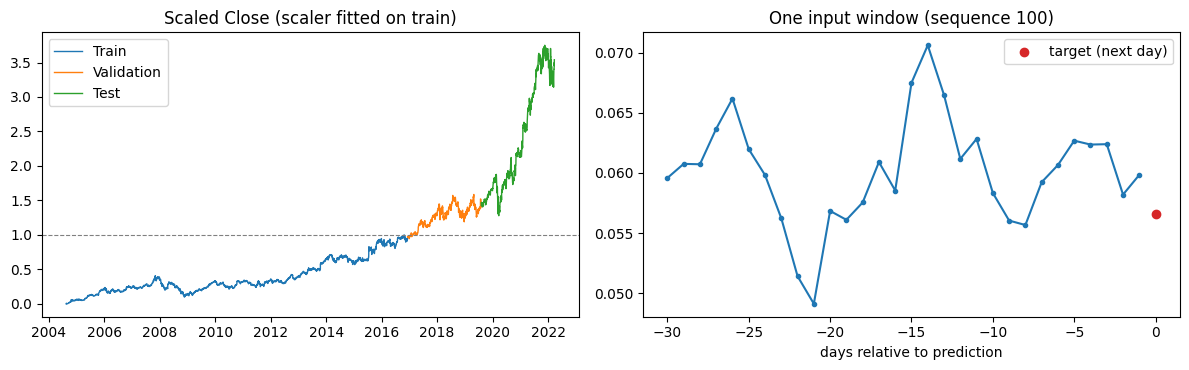

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (a, b) in bounds.items():
    ax[0].plot(df["Date"][a:b], scaled[a:b, target_idx], label=k, linewidth=1)
ax[0].axhline(1, color="grey", linestyle="--", linewidth=0.8)
ax[0].set_title("Scaled Close (scaler fitted on train)")
ax[0].legend()

i = 100
x_days = np.arange(-WINDOW, 0)
ax[1].plot(x_days, data["Train"]["X"][i][:, target_idx], marker="o", markersize=3)
ax[1].scatter([0], [data["Train"]["y"][i]], color="tab:red", zorder=3, label="target (next day)")
ax[1].set_title(f"One input window (sequence {i})")
ax[1].set_xlabel("days relative to prediction")
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "preprocessing_check.png"), dpi=150)
plt.show()

## 7. Save for the model notebooks

In [8]:
np.savez(
    os.path.join(OUT_DIR, "sequences.npz"),
    X_train=data["Train"]["X"], y_train=data["Train"]["y"],
    X_val=data["Validation"]["X"], y_val=data["Validation"]["y"],
    X_test=data["Test"]["X"], y_test=data["Test"]["y"],
    dates_test=data["Test"]["dates"].astype("datetime64[D]").astype(str),
    features=np.array(FEATURES), window=WINDOW,
)
joblib.dump(feature_scaler, os.path.join(OUT_DIR, "feature_scaler.joblib"))
joblib.dump(target_scaler, os.path.join(OUT_DIR, "target_scaler.joblib"))
print(sorted(os.listdir(OUT_DIR)))

#in the next notebook:
#d = np.load("../data/processed/sequences.npz"); X_train, y_train = d["X_train"], d["y_train"]
#target_scaler = joblib.load("../data/processed/target_scaler.joblib")

['feature_scaler.joblib', 'sequences.npz', 'target_scaler.joblib']
